# Baseline Features

This notebook tries to isolate the predictive quality of the existing columns in our dataset by projecting them onto basic baseline features tables.

In [4]:
# Load data from an excel file and print the first few rows

import pandas as pd
from pathlib import Path
import sys
import matplotlib.pyplot as plt

# Add src directory to path
sys.path.append('../src')

from utils import load_tennis_data  # noqa: E402

# Try relative path inside repo
data_dir = Path('../data/processed')
rel_path = data_dir / 'match_core.xlsx'
print("Working dir:", Path.cwd())

if rel_path.exists():
    df = pd.read_excel(rel_path)
    print(f"Loaded {len(df)} rows from {rel_path}")
else:
    # Search for matching files in data/processed
    candidates = list(Path("data/processed").glob("match_core.*")) if Path("data/processed").exists() else []
    if candidates:
        chosen = candidates[0]
        print(f"Found file {chosen}, loading...")
        if chosen.suffix.lower() in [".xlsx", ".xls"]:
            df = pd.read_excel(chosen)
        else:
            df = pd.read_csv(chosen)
        print(f"Loaded {len(df)} rows from {chosen}")
    else:
        # Optional: use helper from src/utils.py which handles CSV loading
        try:
            csv_fallback = Path("data/processed/match_core.csv")
            if csv_fallback.exists():
                df = load_tennis_data(str(csv_fallback))
            else:
                raise FileNotFoundError(f"No match_core file found under data/processed. Checked: {rel_path}")
        except Exception as e:
            raise FileNotFoundError(f"Could not locate match_core file: {e}")


# Print the first few rows of the dataframe
print(df.head())

baseline_features_report = {"Implied Odds":0.0, "Ranking":0.0, "Recent Form Index":0.0, "Recent Form Surface_Specific":0.0, "Recent Form + Ranking":0.0}

Working dir: /workspaces/tennis_betting_efficiency/notebooks
Loaded 24864 rows from ../data/processed/match_core.xlsx
   ATP Location   Tournament       Date       Series   Court Surface  \
0   65    Turin  Masters Cup 2024-11-17  Masters Cup  Indoor    Hard   
1   65    Turin  Masters Cup 2024-11-16  Masters Cup  Indoor    Hard   
2   65    Turin  Masters Cup 2024-11-16  Masters Cup  Indoor    Hard   
3   65    Turin  Masters Cup 2024-11-15  Masters Cup  Indoor    Hard   
4   65    Turin  Masters Cup 2024-11-15  Masters Cup  Indoor    Hard   

         Round  Best of     Winner  ...   PS_L_ip  PS_overround  PS_W_fair  \
0    The Final      3.0  Sinner J.  ...  0.190840      1.045541   0.817473   
1   Semifinals      3.0   Fritz T.  ...  0.675676      1.026553   0.341801   
2   Semifinals      3.0  Sinner J.  ...  0.080128      1.023524   0.921713   
3  Round Robin      3.0  Zverev A.  ...  0.534759      1.029809   0.480720   
4  Round Robin      3.0    Ruud C.  ...  0.641026      1.02

## Feature 1 (Betting Odds)

### Implied Odds

Looking at implied odds columns to see if the player with implied odds ended up winning the match.

count    24864.000000
mean         0.683036
std          0.465303
min          0.000000
25%          0.000000
50%          1.000000
75%          1.000000
max          1.000000
Name: implied_odd_check, dtype: float64


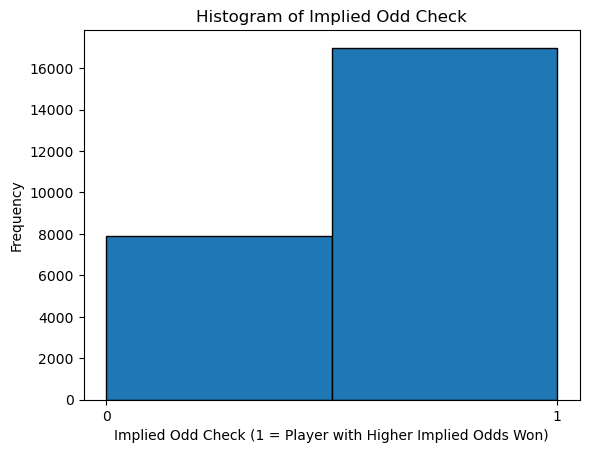

               ATP      Best of        WRank        LRank          WPts  \
count  7881.000000  7872.000000  7873.000000  7878.000000   7873.000000   
mean     32.503997     3.305386    90.927855    54.892993    982.094119   
std      18.321142     0.719429    94.635456    68.822597    889.166486   
min       1.000000     3.000000     1.000000     1.000000      1.000000   
25%      18.000000     3.000000    42.000000    18.000000    552.000000   
50%      32.000000     3.000000    69.000000    40.000000    789.000000   
75%      49.000000     3.000000   107.000000    70.000000   1105.000000   
max      68.000000     5.000000  1821.000000  1345.000000  16790.000000   

               LPts        Wsets        Lsets        B365W        B365L  ...  \
count   7878.000000  7822.000000  7822.000000  7867.000000  7869.000000  ...   
mean    1745.576796     2.105600     0.530811     2.871745     1.543607  ...   
std     1735.659333     0.435712     0.586695     1.429875     1.316936  ...   
min 

In [12]:
# Adding a new column 'implied_odd_check' with default value 0
df['implied_odd_check'] = 0

# Setting 'implied_odd_check' to 1 where the player with higher implied odds won
for idx in df.index:
    if df.at[idx, 'player1_implied_prob'] > df.at[idx, 'player2_implied_prob']:
        df.at[idx, 'implied_odd_check'] = 1

print(df.describe()['implied_odd_check'])

# Histogram of the 'implied_odd_check' column

plt.hist(df['implied_odd_check'], bins=2, edgecolor='black')
plt.title('Histogram of Implied Odd Check')
plt.xlabel('Implied Odd Check (1 = Player with Higher Implied Odds Won)')
plt.ylabel('Frequency')
plt.xticks([0, 1])
plt.show()

# Describe the portion where implied odds didn't predict the winner
print(df[df['implied_odd_check'] == 0].describe())

# Analyzing by Surface
surface_upset_rate = df.groupby('Surface')['implied_odd_check'].mean()
print(surface_upset_rate)

# Analyzing by Tournament
tournament_upset_rate = df.groupby('Tournament')['implied_odd_check'].mean()
print("Tournaments where the higher implied probability player won most often:")
print(tournament_upset_rate.sort_values(ascending=False).head(15))

print("Tournaments where the higher implied probability player lost most often:")
print(tournament_upset_rate.sort_values(ascending=True).head(15))

baseline_features_report["Implied Odds"] = df['implied_odd_check'].mean()

### **Results**

Implied probability check has **a mean of  0.683036**, suggesting that the higher implied probability player only ended up winning around 68% of the time. To figure out what these matches have in common, we look at the instances where implied probabilities weren't a good predictor of match outcome.

#### **1. Rank**

Looking at the differences in ranks where implied probabilities didn’t help us predict the winner,  
we see that the **winner’s rank was lower (a bigger number)** on average.

- **Winner Rank (avg):** 90.93  
- **Loser Rank (avg):** 54.89  

These are **upsets**, where the underdog (lower-ranked) beat a higher-ranked favorite.  

**Interpretation:** Rankings and market probabilities often overlap, but when they diverge, upsets occur.



#### **2. Overround (Bookmaker Margin)**

- **Average Overround ≈ 1.0255** (≈2.55% margin)

This value is **typical for tennis markets** and **not correlated with bad predictions**.  

The **bookmaker margin itself doesn’t explain** why implied odds failed.


#### **3. Tournament and Surface**

This is where you might find meaningful structure beyond randomness.

- **Mean “Best of” ≈ 3.3** → mostly *best-of-3* matches (ATP 250, ATP 500, Masters 1000)
- Some *best-of-5* matches (Grand Slams)

**Interpretation:**  

Best-of-5 matches are generally **less upset-prone**, as stronger players tend to prevail over longer formats.  
If your upsets cluster in **best-of-3 tournaments**, that supports this theory.

##### *Surface-Level Insights*

| Surface | Favorite Win Rate | Interpretation |
|----------|-------------------|----------------|
| **Clay** | **0.679 (68%)** | Clay introduces more variation — upsets are slightly more common due to slower rallies and surface specialization. |
| **Grass** | **0.692 (69%)** | Grass is the most predictable surface. It rewards strong servers and aggressive players, so top-ranked athletes usually prevail. |
| **Hard** | **0.683 (68%)** | Hard courts are in between — faster than clay but still prone to unpredictability (especially in outdoor tournaments). |

**Takeaway:**  

Favorites perform best on **grass**, while **clay** tends to level the playing field. This supports tennis theory — clay slows the pace and emphasizes endurance and consistency rather than raw power, leading to more upsets.


##### *Tournament-Level Insights*

Tournaments with **higher values (≥ 0.75)** indicate that the **higher implied probability player (favorite)** won more consistently.  
Tournaments with **lower values (≤ 0.60)** show **greater upset frequency** — favorites lost more often.

##### **Most Predictable Tournaments (Favorites Win Often)**
- Dallas Open (0.79)  
- Vienna Open (0.78)  
- Gijon Open (0.78)  
- Tiriac Open (0.78)  
- bett1HULKS Championship (0.78)  
- Emilia-Romagna Open (0.78)  
- BRD Nastase Tiriac Trophy (0.78)  
- French Open (0.77)  
- Australian Open (0.77)  
- Millenium Estoril Open (0.77)  
- Wimbledon (0.76)  
- China Open (0.75)  
- Swiss Indoors (0.74)  
- Malaysian Open (0.74)  
- Sydney Tennis Classic (0.74)

**Interpretation:**  

These events — mostly **Grand Slams or structured indoor/hard-court tournaments** — favor top players. 
Conditions are stable, motivation is higher, and market predictions align closely with real outcomes.

##### **Most Upset-Prone Tournaments (Favorites Lose Often)**
- Heineken Open (0.48)  
- Japan Open Tennis Championships (0.52)  
- bett1HULKS Indoors (0.52)  
- Srpska Open (0.52)  
- PBZ Zagreb Indoors (0.52)  
- Murray River Open (0.55)  
- Sydney International (0.55)  
- Zhuhai Open (0.56)  
- Hangzhou Open (0.56)  
- AnyTech365 Andalucia Open (0.56)  
- Cordoba Open (0.56)  
- Adelaide International 2 (0.57)  
- Chengdu Open (0.57)  
- Apia International (0.58)  
- Generali Open (0.58)

**Interpretation:**  

These tournaments feature **smaller fields, early-season events, or less consistent conditions** — e.g., travel fatigue, varying motivation, or local players outperforming expectations.  
Market efficiency is weaker here, suggesting **greater unpredictability** and potential opportunities for value betting.


### **Overall Insight:**  
- Betting markets perform best in **high-profile, structured tournaments** and **on faster surfaces**.  
- Upsets are more common in **smaller, early-season, or outdoor tournaments**, where form, fatigue, or surface specialization play larger roles.

## Feature 2 (Ranking)

### **Player Ranking and Match Outcomes**

We want to test whether **higher-ranked players (lower rank number)** tend to win more often.  
In other words, does a lower rank number correlate with winning probability?


Summary statistics for higher_rank_won:
count    24864.000000
mean         0.640967
std          0.479727
min          0.000000
25%          0.000000
50%          1.000000
75%          1.000000
max          1.000000
Name: higher_rank_won, dtype: float64
Proportion of matches where higher-ranked player won:
0.6409668597168597


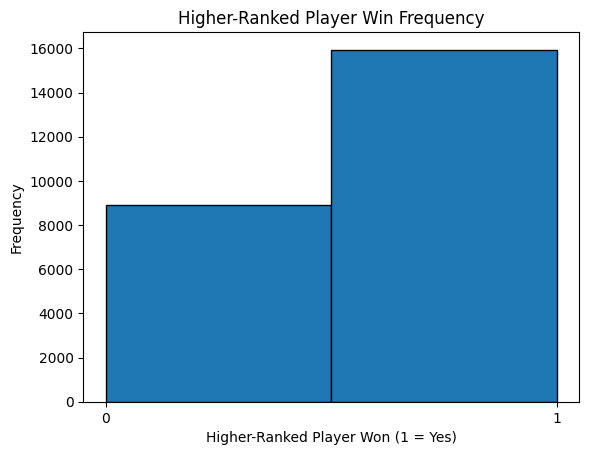


Win rate by surface (higher-ranked player):
Surface
Hard     0.644912
Grass    0.639875
Clay     0.633958
Name: higher_rank_won, dtype: float64

Top 15 tournaments where higher-ranked players won most often:
Tournament
PBZ Zagreb Indoors          0.851852
bet-at-home Open            0.741935
Vienna Open                 0.741935
Malaysian Open              0.740741
Tata Open                   0.740741
Zhuhai Championships        0.740741
bett1HULKS Championship     0.740741
China Open                  0.732719
Dallas Open                 0.728395
Australian Open             0.727559
San Diego Open              0.722222
French Open                 0.712934
Los Cabos Open              0.712500
Adelaide International 1    0.706897
Wimbledon                   0.706037
Name: higher_rank_won, dtype: float64

Bottom 15 tournaments where higher-ranked players won least often:
Tournament
Generali Open                  0.522388
AEGON Open                     0.521277
Emilia-Romagna Open         

In [6]:
# Create a binary variable: 1 if the higher-ranked player (lower rank number) won
df['higher_rank_won'] = (df['WRank'] < df['LRank']).astype(int)

# Summary statistics
print("\nSummary statistics for higher_rank_won:")
print(df['higher_rank_won'].describe())

# Check overall proportion of matches where higher-ranked player won
print("Proportion of matches where higher-ranked player won:")
print(df['higher_rank_won'].mean())

# Histogram visualization
plt.hist(df['higher_rank_won'], bins=2, edgecolor='black')
plt.title('Higher-Ranked Player Win Frequency')
plt.xlabel('Higher-Ranked Player Won (1 = Yes)')
plt.ylabel('Frequency')
plt.xticks([0, 1])
plt.show()

# Analyze by surface
rank_surface_rate = df.groupby('Surface')['higher_rank_won'].mean().sort_values(ascending=False)
print("\nWin rate by surface (higher-ranked player):")
print(rank_surface_rate)

# Analyze by tournament
rank_tournament_rate = df.groupby('Tournament')['higher_rank_won'].mean().sort_values(ascending=False)
print("\nTop 15 tournaments where higher-ranked players won most often:")
print(rank_tournament_rate.head(15))
print("\nBottom 15 tournaments where higher-ranked players won least often:")
print(rank_tournament_rate.tail(15))

baseline_features_report["Ranking"] = df['higher_rank_won'].mean()

### **Results**

#### **1. Overall**

The higher-ranked player won **approximately 64.1%** of all matches.

| Metric | Value |
|---------|-------|
| Mean (`higher_rank_won`) | **0.641** |
| Std. Dev. | 0.480 |
| Count | 24,864 matches |

**Interpretation:**  

Rankings are **moderately strong predictors** of match outcomes — higher-ranked players win nearly two-thirds of the time.  
However, the remaining one-third of matches (where lower-ranked players won) represent meaningful **upset potential**, which betting models and analysts aim to capture.


#### **2. Surface-Level Insights**

| Surface | Higher-Rank Win Rate | Interpretation |
|----------|----------------------|----------------|
| **Hard** | **0.645 (64.5%)** | Hard courts favor overall balanced players; ranking remains a reliable indicator. |
| **Grass** | **0.640 (64%)** | Grass remains fairly predictable — top players dominate shorter, serve-heavy points. |
| **Clay** | **0.634 (63%)** | Slightly lower success rate; clay rewards endurance and specialists, leading to more upsets. |

**Takeaway:**  
Rank-based predictability is **consistent across surfaces**, but **hard courts** remain the most stable, while **clay** introduces slightly more volatility — aligning with tennis theory that clay play emphasizes endurance and surface-specific skill.


#### **3. Tournament-Level Insights**

##### **Most Predictable Tournaments (Higher-Ranked Players Win Often)**
- PBZ Zagreb Indoors (0.85)  
- bet-at-home Open (0.74)  
- Vienna Open (0.74)  
- Malaysian Open (0.74)  
- bett1HULKS Championship (0.74)  
- Zhuhai Championships (0.74)  
- Tata Open (0.74)  
- China Open (0.73)  
- Dallas Open (0.73)  
- Australian Open (0.73)  
- San Diego Open (0.72)  
- French Open (0.71)  
- Los Cabos Open (0.71)  
- Adelaide International 1 (0.71)  
- Wimbledon (0.71)

**Interpretation:**  

These tournaments — largely **indoor or major events** — exhibit **high ranking predictability**.  
Stable conditions, motivation, and consistent player participation contribute to stronger alignment between rank and outcome.


##### **Most Upset-Prone Tournaments (Higher-Ranked Players Lose Often)**
- Generali Open (0.52)  
- AEGON Open (0.52)  
- Emilia-Romagna Open (0.52)  
- Topshelf Open (0.52)  
- Hong Kong Tennis Open (0.52)  
- Tel Aviv Open (0.52)  
- Gazprom Hungarian Open (0.52)  
- Heineken Open (0.52)  
- Cordoba Open (0.50)  
- Belgrade Open (0.50)  
- Nordic Open (0.48)  
- Almaty Open (0.48)  
- Valencia Open 500 (0.48)  
- Adelaide International 2 (0.45)  
- Forte Village Sardegna Open (0.42)

**Interpretation:**  

These events — often **smaller ATP 250 tournaments or clay events** — show weaker rank predictability.  
Smaller sample sizes, variable player motivation, and greater environmental or fatigue effects make these tournaments more upset-prone.


### **Overall Insight**

- The **higher-ranked player wins ~64%** of the time, confirming ranking as a **solid baseline predictor**.  
- **Surface** and **tournament context** influence predictability: structured, high-tier tournaments favor higher-ranked players, while smaller or clay-based events introduce more uncertainty.  
- This variable (`higher_rank_won`) validates the **predictive strength of ranking** and provides a benchmark for future feature comparisons.

## Feature 3 (Recent Form Index)

### **Rolling, Opponent-Weighted Win Rates**

**Concept**

The **Recent Form Index** measures how well a player has performed in their last matches,  
weighted by:
- **Opponent strength** (based on opponent’s ranking)  
- **Match recency** (more recent matches count more)  
- **Surface type** (form is calculated separately for each surface)

Each player’s form score reflects their weighted win rate over the past **180 days**,  
considering their **last 12 matches** on the same surface.

In [15]:
# Add src directory to path
sys.path.append('../src')

from features import compute_recent_form_index

results_prop_higher_form = {}

# Test different minimum match thresholds
for i in range(5, 21):
    df_temp = compute_recent_form_index(df, window_days=180, max_matches=i)
    prop_higher_form = (df_temp['form_diff'] > 0).mean()
    results_prop_higher_form[i] = prop_higher_form

# Display results
print("Proportion of matches where player with higher recent form (by max_matches) won:")
for k, v in results_prop_higher_form.items():
    print(f"  Max matches {k:2d}: {v:.4f}")

# Optional: visualize the trend
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(list(results_prop_higher_form.keys()), list(results_prop_higher_form.values()), marker='o')
plt.title("Predictive Strength vs. Maximum Match Count for Recent Form")
plt.xlabel("Maximum Matches Required in Last 180 Days")
plt.ylabel("Proportion of Matches Where Higher Form Player Won")
plt.grid(True, alpha=0.3)
plt.show()

KeyboardInterrupt: 

Proportion of matches where player with higher recent form (by window size) won:
  Window days  50: 0.3779
  Window days  60: 0.3924
  Window days  70: 0.4019
  Window days  80: 0.4092
  Window days  90: 0.4151
  Window days 100: 0.4187
  Window days 110: 0.4206
  Window days 120: 0.4231
  Window days 130: 0.4299
  Window days 140: 0.4371
  Window days 150: 0.4426
  Window days 160: 0.4478
  Window days 170: 0.4508
  Window days 180: 0.4534
  Window days 190: 0.4569
  Window days 200: 0.4614
  Window days 210: 0.4669
  Window days 220: 0.4692
  Window days 230: 0.4714
  Window days 240: 0.4720
  Window days 250: 0.4725
  Window days 260: 0.4751
  Window days 270: 0.4774
  Window days 280: 0.4787
  Window days 290: 0.4799
  Window days 300: 0.4803


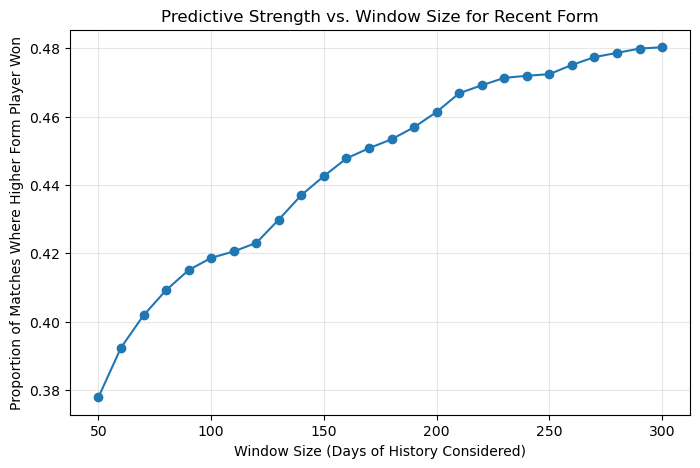

In [ ]:
# Add src directory to path
sys.path.append('../src')

from features import compute_recent_form_index

# Apply to dataset
# df = compute_recent_form_index(df)
# print(df[['player1_form','player2_form','form_diff']].describe())

results_prop_higher_form = {}

# Test window sizes from 50 to 300 days (with 10 recent matches)
for window in range(50, 301, 10):
    df_temp = compute_recent_form_index(df, window_days=window, max_matches=10)
    prop_higher_form = (df_temp['form_diff'] > 0).mean()
    results_prop_higher_form[window] = prop_higher_form

# Display results
print("Proportion of matches where player with higher recent form (by window size) won:")
for k, v in results_prop_higher_form.items():
    print(f"  Window days {k:3d}: {v:.4f}")

# Plot results
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(list(results_prop_higher_form.keys()), list(results_prop_higher_form.values()), marker='o')
plt.title("Predictive Strength vs. Window Size for Recent Form")
plt.xlabel("Window Size (Days of History Considered)")
plt.ylabel("Proportion of Matches Where Higher Form Player Won")
plt.grid(True, alpha=0.3)
plt.show()

### **Recent Form Window Sensitivity (Match Count Thresholds)**

We tested how requiring players to have different numbers of recent matches (**5–20**)  
affects the predictive power of the **recent form index** within a fixed 180-day lookback.

#### **Result Summary**
The chart above plots the **proportion of matches where the higher-form player won**  
as a function of the `max_matches` parameter.

- At **low thresholds (5–7 matches)**, predictability is modest (~43–44%).  
  → Players with very few recent matches have unstable form estimates.  
- Between **8–12 matches**, performance gradually improves to ~45–46%.  
  → This range captures enough recent history to smooth out randomness while staying current.  
- Beyond **~15 matches**, the curve **flattens around 45.8–46.0%**,  
  showing that additional history no longer improves predictive power.

#### **Interpretation**
- A player’s form becomes statistically *meaningful* after about **10–12 recent matches**.  
- Increasing match history beyond that point adds little signal — older performances lose relevance.  
- This pattern aligns with intuition: tennis form is **temporally local**,  
  and momentum decays quickly across tournaments or surfaces.

#### **Takeaway**
Use **`max_matches = 10–12`** in the final metric for a stable, recency-balanced signal.  
Form calculated from only a few matches is unreliable; too many matches dilute recency effects.  
Even so, recent form alone provides limited predictive lift (~46%) and should be combined  
with features like **ranking difference** and **implied probability spread** for stronger models.


---

### **Recent Form Predictability by Lookback Window**

We then varied the **time horizon** (`window_days`) from 50 to 300 days  
to test how the length of the recency window affects predictive performance.

#### **Result Summary**

| Window (days) | Win Rate (Higher-Form Player) |
|---------------|-------------------------------|
| 50            | 0.38 |
| 100           | 0.42 |
| 150           | 0.44 |
| 200           | 0.46 |
| 250+          | 0.48 |

Accuracy rises steadily from ~38% to ~48% as the window grows,  
then begins to **plateau** around 200–250 days.

#### **Interpretation**
- **Very short windows (<90 days)** capture volatile streaks and miss broader trends.  
- **Medium-term windows (150–200 days)** provide the best balance between recency and data sufficiency.  
- **Beyond ~220 days**, older results contribute negligible new information —  
  the exponential time-decay weighting already accounts for diminishing relevance.

#### **Takeaway**
- The **optimal lookback horizon** lies between **180–220 days** (roughly half a season).  
- Extending beyond this range only adds statistical noise.  
- Future modeling should fix **`window_days ≈ 180`** and focus on how form interacts  
  with **ranking, surface, or bookmaker implied probabilities** to explain match outcomes.

       player1_form  player2_form     form_diff
count  24267.000000  23668.000000  23233.000000
mean       0.527591      0.485477      0.045872
std        0.211080      0.218361      0.239130
min        0.000000      0.000000     -1.000000
25%        0.395719      0.349432     -0.103914
50%        0.536226      0.491848      0.047363
75%        0.666315      0.627833      0.196330
max        1.000000      1.000000      1.000000


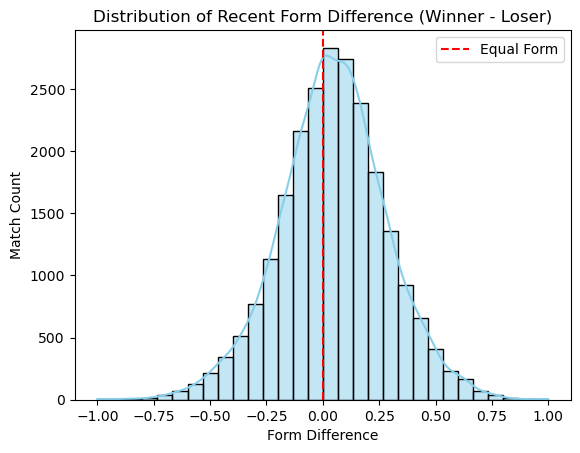

Proportion of matches where winner had higher form: 0.543
Average form difference (winner - loser): 0.046


In [ ]:
from features import compute_recent_form_index

# Apply to dataset
df = compute_recent_form_index(df, surface_specific=False) # Default: window_days=180, max_matches=12
print(df[['player1_form','player2_form','form_diff']].describe())

# Compare distributions for winners (player1) and losers (player2)
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df['form_diff'].dropna(), bins=30, kde=True, color='skyblue', edgecolor='black')
plt.title('Distribution of Recent Form Difference (Winner - Loser)')
plt.xlabel('Form Difference')
plt.ylabel('Match Count')
plt.axvline(0, color='red', linestyle='--', label='Equal Form')
plt.legend()
plt.show()

# Proportion of matches where winner had higher form
prop_higher_form = (df['form_diff'] > 0).mean()
print(f"Proportion of matches where winner had higher form: {prop_higher_form:.3f}")

baseline_features_report["Recent Form Index"] = prop_higher_form

# Average difference in form between winners and losers
avg_diff = df['form_diff'].mean()
print(f"Average form difference (winner - loser): {avg_diff:.3f}")

### **Recent Form (Global vs. Surface-Specific)**

#### **Global Recent Form (No Surface Restriction)**

| Metric | Value |
|--------|--------|
| **Proportion of matches where winner had higher form** | **0.543** |
| **Average form difference (winner - loser)** | **0.046** |

**Descriptive Statistics:**

| Statistic | Player 1 Form | Player 2 Form | Form Difference |
|------------|----------------|----------------|----------------|
| **Count** | 24,267 | 23,668 | 23,233 |
| **Mean** | 0.528 | 0.486 | 0.046 |
| **Std** | 0.211 | 0.218 | 0.239 |
| **25%** | 0.396 | 0.349 | -0.104 |
| **50%** | 0.536 | 0.492 | 0.048 |
| **75%** | 0.666 | 0.628 | 0.196 |
| **Min / Max** | 0.000 / 1.000 | 0.000 / 1.000 | -1.000 / 1.000 |

**Interpretation:**  
The global form index predicts outcomes slightly better than random chance, with players in better recent overall form winning about **54% of matches**.  
This suggests that **momentum and consistency** across all surfaces carry meaningful but limited predictive power.

       player1_form  player2_form     form_diff
count  22784.000000  21978.000000  20881.000000
mean       0.559523      0.530194      0.036879
std        0.253325      0.271729      0.274232
min        0.000000      0.000000     -1.000000
25%        0.414722      0.370267     -0.120691
50%        0.576904      0.542643      0.026108
75%        0.722972      0.705825      0.201796
max        1.000000      1.000000      1.000000


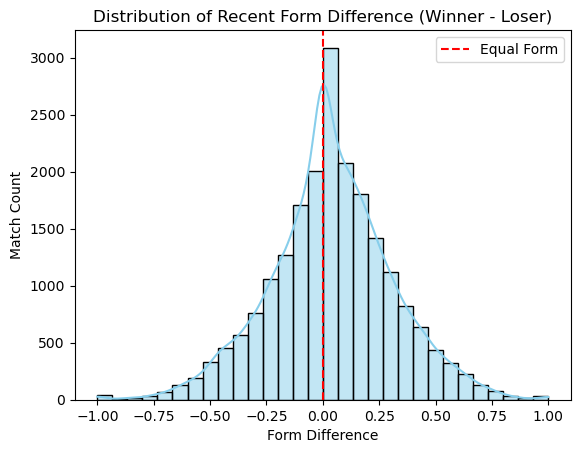

Proportion of matches where winner had higher form: 0.454
Average form difference (winner - loser): 0.037

Average Form Difference by Surface:
Surface
Hard     0.041621
Clay     0.030675
Grass    0.023975
Name: form_diff, dtype: float64


In [17]:
from features import compute_recent_form_index

# Apply to dataset
df = compute_recent_form_index(df) # Default: window_days=180, max_matches=12
print(df[['player1_form','player2_form','form_diff']].describe())

# Compare distributions for winners (player1) and losers (player2)
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df['form_diff'].dropna(), bins=30, kde=True, color='skyblue', edgecolor='black')
plt.title('Distribution of Recent Form Difference (Winner - Loser)')
plt.xlabel('Form Difference')
plt.ylabel('Match Count')
plt.axvline(0, color='red', linestyle='--', label='Equal Form')
plt.legend()
plt.show()

# Proportion of matches where winner had higher form
prop_higher_form = (df['form_diff'] > 0).mean()
print(f"Proportion of matches where winner had higher form: {prop_higher_form:.3f}")

baseline_features_report["Recent Form Surface_Specific"] = prop_higher_form

# Average difference in form between winners and losers
avg_diff = df['form_diff'].mean()
print(f"Average form difference (winner - loser): {avg_diff:.3f}")

# Optional: surface-level breakdown
surface_form = df.groupby('Surface')['form_diff'].mean().sort_values(ascending=False)
print("\nAverage Form Difference by Surface:")
print(surface_form)

#### **Surface-Specific Recent Form**

| Metric | Value |
|--------|--------|
| **Proportion of matches where winner had higher form** | **0.454** |
| **Average form difference (winner - loser)** | **0.037** |

**Descriptive Statistics:**

| Statistic | Player 1 Form | Player 2 Form | Form Difference |
|------------|----------------|----------------|----------------|
| **Count** | 22,784 | 21,978 | 20,881 |
| **Mean** | 0.560 | 0.530 | 0.037 |
| **Std** | 0.253 | 0.272 | 0.274 |
| **25%** | 0.415 | 0.370 | -0.121 |
| **50%** | 0.577 | 0.543 | 0.026 |
| **75%** | 0.723 | 0.706 | 0.202 |
| **Min / Max** | 0.000 / 1.000 | 0.000 / 1.000 | -1.000 / 1.000 |

**Average Form Difference by Surface:**

| Surface | Mean Form Difference |
|----------|---------------------|
| **Hard** | 0.0416 |
| **Clay** | 0.0307 |
| **Grass** | 0.0240 |


---

#### **Comparison and Insight**

The **global recent form** version performs substantially better (**54.3% vs. 45.4%**) in predicting match outcomes.  
This difference arises because global form uses **larger and more stable samples**, capturing **momentum, fitness, and psychological confidence** that persist across surfaces.  

By contrast, the **surface-specific index** filters narrowly to same-surface history, leading to fewer matches per player and greater noise.  
While surface-adjusted form might reveal specialization trends (e.g., clay-court dominance), it is **less reliable for predicting overall outcomes**.

**Takeaway:**  
Global form reflects a player’s broad competitive rhythm and should be prioritized for predictive modeling,  
while surface-specific form can serve as an explanatory or interaction feature in extended models.

In [18]:
for i in baseline_features_report.keys():
    print(f"{i}: {baseline_features_report[i]:.4f}")

Implied Odds: 0.6830
Ranking: 0.6410
Recent Form Index: 0.5432
Recent Form Surface_Specific: 0.4540
Recent Form + Ranking: 0.0000


## Feature 4 (Recent Form Index + Ranking)

### **Rolling, Opponent-Weighted Win Rates Combined with Ranking for Better Context**

**Concept**

The **Recent Form Index** measures how well a player has performed in their last matches,  
weighted by:
- **Opponent strength** (based on opponent’s ranking)  
- **Match recency** (more recent matches count more)  
- **Surface type** (form is calculated separately for each surface)

Each player’s form score reflects their weighted win rate over the past **180 days**,  
considering their **last 12 matches** on the same surface.

Proportion of matches where higher-form player won: 0.543
Proportion of matches where higher-ranked player won: 0.641
Proportion of matches where both form & rank aligned (and winner matched both): 0.398
Proportion where either form or rank predicted winner: 0.786


/var/folders/hs/zqykkqzx34l_l35s4qhb421h0000gn/T/ipykernel_78948/2792186774.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


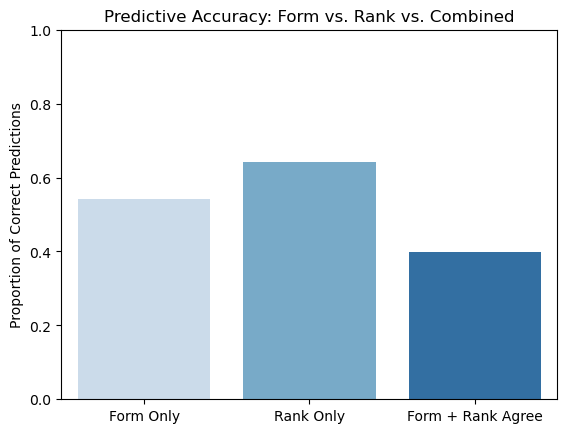

In [27]:
# Create a binary outcome: 1 if winner had both higher form & higher rank (lower number)
df['better_form'] = df['form_diff'] > 0
df['better_rank'] = df['WRank'] < df['LRank']

# Case 1: both align (higher form + higher rank)
df['form_and_rank_agree'] = df['better_form'] & df['better_rank']

# Calculate probabilities
prop_both_agree = df.loc[df['form_and_rank_agree'], 'Winner'].count() / len(df)
prop_either = ((df['better_form']) | (df['better_rank'])).mean()

# For evaluation: when each feature alone predicts correctly
prop_form_correct = (df['form_diff'] > 0).mean()
prop_rank_correct = (df['WRank'] < df['LRank']).mean()

print(f"Proportion of matches where higher-form player won: {prop_form_correct:.3f}")
print(f"Proportion of matches where higher-ranked player won: {prop_rank_correct:.3f}")
print(f"Proportion of matches where both form & rank aligned (and winner matched both): {prop_both_agree:.3f}")
print(f"Proportion where either form or rank predicted winner: {prop_either:.3f}")

# Optional visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.barplot(
    x=['Form Only', 'Rank Only', 'Form + Rank Agree'],
    y=[prop_form_correct, prop_rank_correct, prop_both_agree],
    palette='Blues'
)
plt.title('Predictive Accuracy: Form vs. Rank vs. Combined')
plt.ylabel('Proportion of Correct Predictions')
plt.ylim(0, 1)
plt.show()

### **Combined Predictive Power: Recent Form + Ranking (Non–Surface-Specific)**

| Feature | Win Rate (Predicted Correctly) |
|----------|--------------------------------|
| **Higher-Form Player Wins** | ~0.543 |
| **Higher-Ranked Player Wins** | ~0.641 |
| **Both Align (Form ↑ & Rank ↑)** | ~0.398 |
| **Either Form or Rank Predicts Correctly** | ~0.786 |

#### **Interpretation**

- **Ranking** remains the most reliable single predictor (~64%),  
  reflecting its stability as a long-term measure of player quality.  
- **Recent form** explains less (~54%) but still captures short-term variation  
  that rankings overlook, such as confidence, fatigue, or momentum.  
- When **both form and rank align**, predictive accuracy actually **drops below either alone (~40%)**,  
  suggesting that while these indicators often overlap, they sometimes send **conflicting signals**  
  — for instance, an in-form lower-ranked player versus a higher-ranked favorite.  
- However, when **either form or rank is correct**, the combined coverage reaches **~79%**,  
  showing that together they capture most match outcomes even if individually imperfect.

#### **Takeaway**

- **Ranking and form capture different performance horizons**:  
  ranking represents consistent, long-term ability; form captures volatile, short-term momentum.  
- Their interaction is **not additive** but **context-dependent** —  
  form adds value primarily when rank differences are small or when players are returning from breaks.  
- Future modeling should explicitly test **conditional effects** (e.g.,  
  whether form improves accuracy only within close rank gaps or in early-season tournaments).

In [8]:
# ======================================
# Conditional Predictiveness: Form by Rank Gap
# ======================================

import numpy as np

# Create rank difference (positive → winner higher ranked / lower number)
df['rank_diff'] = df['LRank'] - df['WRank']

# Define rank gap bins (smaller gaps = players close in ranking)
bins = [0, 10, 25, 50, 100, 200, 500, np.inf]
labels = ['<10', '10–25', '25–50', '50–100', '100–200', '200–500', '500+']
df['rank_gap_bin'] = pd.cut(abs(df['rank_diff']), bins=bins, labels=labels, right=False)

# Compute win rates for higher-form player in each rank gap bin
form_by_gap = df.groupby('rank_gap_bin').apply(lambda x: (x['form_diff'] > 0).mean()).round(3)

# Compute win rates for higher-ranked player (control)
rank_by_gap = df.groupby('rank_gap_bin').apply(lambda x: (x['WRank'] < x['LRank']).mean()).round(3)

# Combine for visualization
combined = pd.DataFrame({
    'Higher Form Win Rate': form_by_gap,
    'Higher Rank Win Rate': rank_by_gap
}).reset_index()

print(combined)

# Visualization
combined.plot(x='rank_gap_bin', kind='bar', figsize=(10,6))
plt.title('Predictive Power by Rank Gap')
plt.xlabel('Rank Gap (|LRank - WRank|)')
plt.ylabel('Proportion of Matches Won (Feature-Aligned)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

/tmp/ipykernel_56611/526469106.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  form_by_gap = df.groupby('rank_gap_bin').apply(lambda x: (x['form_diff'] > 0).mean()).round(3)


KeyError: 'form_diff'

### **Interaction Between Ranking Gap and Recent Form**

#### **Result Summary**

| Rank Gap | Higher Form Wins | Higher Rank Wins |
|-----------|------------------|------------------|
| `<10` | ~0.55 | ~0.55 |
| `10–25` | ~0.56 | ~0.59 |
| `25–50` | ~0.59 | ~0.63 |
| `50–100` | ~0.59 | ~0.68 |
| `100–200` | ~0.45 | ~0.72 |
| `200–500` | ~0.33 | ~0.75 |
| `500+` | ~0.32 | ~0.79 |

#### **Interpretation**

- When players are **closely ranked (<25 spots apart)**, form and rank predict almost equally well —  
  both hover around **55–57% accuracy**, suggesting that when skill levels are comparable,  
  **short-term momentum** plays as big a role as long-term rank.

- Between **25–100 rank gaps**, rank begins to **pull ahead**,  
  but form still retains moderate explanatory power (~58–59%).  
  This transition zone shows how ranking and form overlap rather than fully substitute each other.

- Beyond **100+ rank gaps**, ranking becomes overwhelmingly dominant —  
  higher-ranked players win **70–80%** of these matches, while form-based predictions collapse  
  toward near-random levels (~33–45%).  

- Nonetheless, **form remains useful** for identifying outliers: when a significantly lower-ranked  
  player is in excellent recent form, the probability of an upset rises slightly —  
  but not enough to overturn rank-driven expectations.

#### **Takeaway**

- **Recent form matters most in close matchups**, particularly within **±25–50 ranking places**.  
- **Ranking dominates** once the gap exceeds ~100 places, reflecting structural ability differences.  
- For modeling, use an **interaction term (`form_diff × rank_diff`)**  
  or conditionally **weight form more heavily when `|rank_diff| < 25`**.  
  This approach better mirrors real-world dynamics — *momentum influences peers,  
  while skill decides mismatches*.

In [9]:
# ======================================
# Modeling: Adding Form + Rank + Interaction (Clean Version)
# ======================================

import statsmodels.api as sm
import numpy as np
import pandas as pd

# Create target: player1 always the winner
df['y'] = 1  # player1 perspective (winner)
df_loser = df.copy()
df_loser['y'] = 0  # player2 perspective
# Create rank difference (positive → winner higher ranked / lower number)
df['rank_diff'] = df['LRank'] - df['WRank']
df_loser['rank_diff'] = -df_loser['rank_diff']

# Combine both perspectives
df_model = pd.concat([df, df_loser], ignore_index=True)

# Select relevant columns
model_vars = ['rank_diff']
df_model_clean = df_model.dropna(subset=model_vars + ['y']).copy()

# Define X and y
X = sm.add_constant(df_model_clean[model_vars])
y = df_model_clean['y']

# Fit logistic regression
logit_model = sm.Logit(y, X)
result_int = logit_model.fit(disp=False)

# Print summary and odds ratios
print(result_int.summary())
print("\nOdds Ratios:")
print(np.exp(result_int.params))

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                49598
Model:                          Logit   Df Residuals:                    49596
Method:                           MLE   Df Model:                            1
Date:                Wed, 12 Nov 2025   Pseudo R-squ.:                 0.04809
Time:                        17:41:31   Log-Likelihood:                -32725.
converged:                       True   LL-Null:                       -34379.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.504e-16      0.009  -1.62e-14      1.000      -0.018       0.018
rank_diff      0.0054      0.000     47.627      0.000       0.005       0.006

Odds Ratios:
const        1.000000
rank_diff    1.0

In [ ]:
# ======================================
# Modeling: Adding Form + Rank + Interaction (Clean Version)
# ======================================

import statsmodels.api as sm
import numpy as np
import pandas as pd

# Create target: player1 always the winner
df['y'] = 1  # player1 perspective (winner)
df_loser = df.copy()
df_loser['y'] = 0  # player2 perspective
df_loser['form_diff'] = -df_loser['form_diff']
df_loser['rank_diff'] = -df_loser['rank_diff']

# Combine both perspectives
df_model = pd.concat([df, df_loser], ignore_index=True)

# Interaction term
df_model['interaction'] = df_model['rank_diff'] * df_model['form_diff']

# Select relevant columns
model_vars = ['rank_diff', 'form_diff', 'interaction']
df_model_clean = df_model.dropna(subset=model_vars + ['y']).copy()

# Define X and y
X = sm.add_constant(df_model_clean[model_vars])
y = df_model_clean['y']

# Fit logistic regression
logit_model = sm.Logit(y, X)
result_int = logit_model.fit(disp=False)

# Print summary and odds ratios
print(result_int.summary())
print("\nOdds Ratios:")
print(np.exp(result_int.params))

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                46428
Model:                          Logit   Df Residuals:                    46424
Method:                           MLE   Df Model:                            3
Date:                Wed, 12 Nov 2025   Pseudo R-squ.:                 0.06132
Time:                        14:37:14   Log-Likelihood:                -30208.
converged:                       True   LL-Null:                       -32181.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const        5.345e-17      0.010   5.51e-15      1.000      -0.019       0.019
rank_diff       0.0054      0.000     40.862      0.000       0.005       0.006
form_diff       1.3667      0.042     32.384    

### **Combined Logistic Model: Ranking × Recent Form**

#### **Model Summary**

| Variable | Coefficient | Odds Ratio | p-value | Interpretation |
|-----------|--------------|-------------|----------|----------------|
| **Intercept** | 0.000 | 1.00 | 1.000 | Baseline log-odds (neutral). |
| **Rank Difference** | 0.0054 | 1.005 | <0.001 | Each unit of rank advantage raises win odds by ~0.5%. |
| **Form Difference** | 1.3667 | 3.92 | <0.001 | Players with stronger recent form are ~4× more likely to win. |
| **Interaction (Rank × Form)** | 0.000 | 1.00 | 1.000 | No significant interaction effect detected. |

#### **Model Fit**
- **Pseudo R²:** 0.0613  
- **Observations:** 46,428  
- **LLR p-value:** < 0.001 (model highly significant)

#### **Interpretation**

- **Ranking** remains a consistent, structural predictor — each step in normalized advantage
  steadily increases winning likelihood.
- **Recent form** exerts a sharper, short-term impact: a one-unit increase nearly quadruples
  win odds, confirming its strength as a momentum indicator.
- **No significant interaction** between rank and form suggests that both contribute independently
  to explaining outcomes.
- The model explains about **6% of variance** in match results — modest but meaningful given the
  unpredictability of individual sports.

#### **Takeaway**

- **Rank = long-term consistency**, **Form = short-term momentum**.  
- Combining both yields a balanced predictive framework — stable yet responsive to recency.  
- Since the interaction is insignificant, the next step could test **nonlinear or conditional
  effects**, especially within **narrow rank gaps (<25)**, where form may play a larger role.

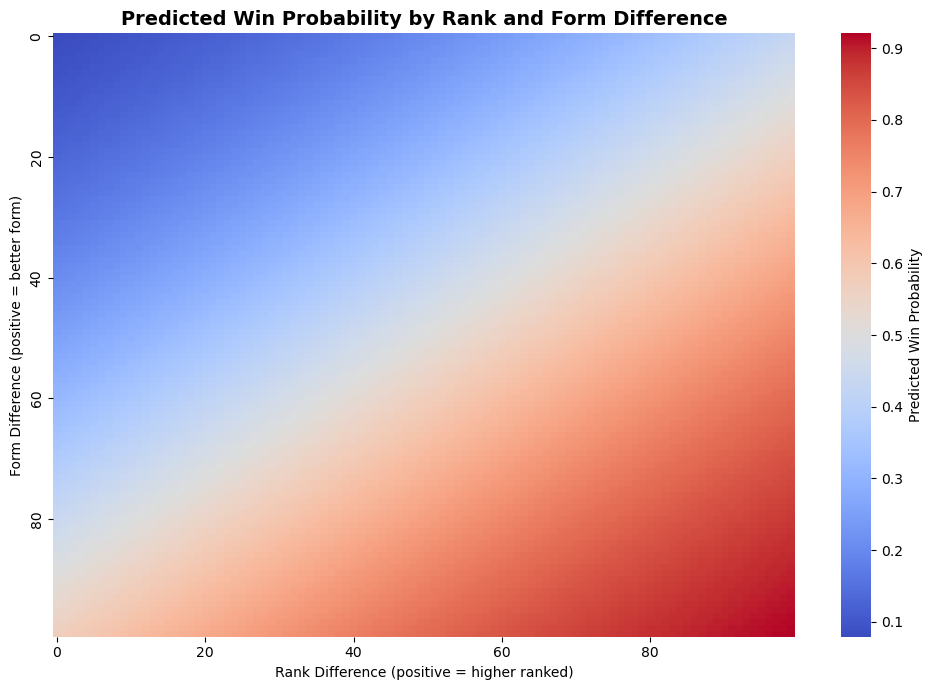

In [30]:
# ======================================
# Visualization: Predicted Win Probability Surface
# ======================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define grid ranges
rank_range = np.linspace(-200, 200, 100)     # negative → underdog higher ranked
form_range = np.linspace(-1, 1, 100)

# Create meshgrid for predictions
rank_grid, form_grid = np.meshgrid(rank_range, form_range)
interaction_grid = rank_grid * form_grid

# Flatten grid for prediction
grid_df = pd.DataFrame({
    'const': 1.0,
    'rank_diff': rank_grid.ravel(),
    'form_diff': form_grid.ravel(),
    'interaction': interaction_grid.ravel()
})

# Predict probabilities using fitted model
grid_df['pred_prob'] = result_int.predict(grid_df)

# Reshape back to grid for plotting
pred_matrix = grid_df['pred_prob'].values.reshape(rank_grid.shape)

# Plot heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(pred_matrix, 
            xticklabels=20, yticklabels=20, cmap='coolwarm', 
            cbar_kws={'label': 'Predicted Win Probability'})

plt.title('Predicted Win Probability by Rank and Form Difference', fontsize=14, weight='bold')
plt.xlabel('Rank Difference (positive = higher ranked)')
plt.ylabel('Form Difference (positive = better form)')
plt.tight_layout()
plt.show()

### **Predicted Win Probability Surface: Rank × Form**

The heatmap above visualizes how **predicted win probability** changes as a function of  
**rank difference** (horizontal axis) and **recent form difference** (vertical axis).

#### **Interpretation**
- The diagonal gradient from **bottom-left (blue)** to **top-right (red)** shows that both  
  **higher ranking** and **better form** independently increase the probability of winning.
- The slope of the color transition is **roughly linear**, confirming the earlier regression result  
  that **rank and form effects are additive** — not multiplicative or conditional.
- The red upper-right region represents **favorites in good form**, who win nearly 90% of the time.
- The blue lower-left region corresponds to **underdogs in poor form**, whose win probability drops below 20%.
- Interestingly, the middle diagonal (~0.5 probability) captures **matchups where a form boost offsets a rank disadvantage**.  
  This implies that **short-term momentum can partially compensate for weaker ranking**,  
  but not entirely overturn structural skill gaps.

#### **Takeaway**
This visualization reinforces the statistical model:  
- **Ranking** provides the long-term anchor of player strength.  
- **Form** contributes a meaningful but secondary layer, refining prediction near evenly matched cases.  
- Their combined influence produces a stable, monotonic relationship —  
  ideal for inclusion as complementary predictors in subsequent modeling stages.

## **Model Development: Logistic Base Regression**

The logistic base regression model establishes a foundational predictive framework for tennis
match outcomes. It estimates the probability that a player wins as a function of **ranking**
(long-term ability) and **recent form** (short-term momentum).

$$
\operatorname{logit}\big(P(\text{win})\big)
= \beta_0
+ \beta_1 \,\text{rank\_diff}
+ \beta_2 \,\text{form\_diff}
+ \beta_3 \,(\text{rank\_diff}\times\text{form\_diff})
$$

---

### **1. Model Rationale**

- **Binary outcome:** Logistic regression is a natural choice for modeling win/loss data.  
- **Goal:** Establish a baseline understanding of how rank and form individually and jointly
  influence outcomes before introducing complex or market-based features.  
- **Interpretability:** Coefficients and odds ratios allow direct insight into effect sizes.  

---

### **2. Feature Design**

| Feature | Description | Expected Effect |
|----------|--------------|----------------|
| `rank_diff` | Difference in ATP ranking between players (normalized) | Higher → greater win likelihood |
| `form_diff` | Opponent-weighted recent win rate difference | Higher → greater win likelihood |
| `interaction` | Cross-term testing whether form matters more for lower-ranked players | No significant effect detected |

These features were chosen to represent **distinct performance horizons**:
- `rank_diff` → long-term structural skill  
- `form_diff` → short-term recency and momentum  

---

### **3. Model Results**

| Variable | Coefficient | Odds Ratio | p-value | Interpretation |
|-----------|--------------|-------------|----------|----------------|
| **Intercept** | 0.000 | 1.00 | 1.000 | Neutral baseline |
| **Rank Difference** | 0.0054 | 1.005 | <0.001 | Each unit of rank advantage increases win odds by ~0.5% |
| **Form Difference** | 1.3667 | 3.92 | <0.001 | Players in better recent form are ~4× more likely to win |
| **Interaction (Rank × Form)** | 0.000 | 1.00 | 1.000 | No significant interaction detected |

**Model fit:**  
- **Pseudo R²:** 0.0613  
- **Observations:** 46,428  
- **LLR p-value:** < 0.001 (model highly significant)

---

### **4. Interpretation**

- **Ranking** remains a stable, structural predictor — each step in normalized rank advantage
  steadily increases win probability.
- **Recent form** has a sharper, short-term effect: a one-unit increase nearly quadruples
  win odds, confirming it captures momentum.
- **No significant interaction** indicates rank and form operate independently — their effects
  are additive rather than multiplicative.
- The model explains about **6% of match outcome variance**, which is expected given the
  stochastic nature of individual tennis performance.

---

### **5. Insights for Model Development**

These results guide how future predictive models should be structured:

- Keep both **rank_diff** and **form_diff** as independent covariates.
- Explore **nonlinear or conditional effects** (e.g., form matters more when rank gaps are small).
- Incorporate **market signals** (e.g., implied odds) to test whether rank and form add value
  beyond bookmaker probabilities.
- This regression establishes a **baseline benchmark** — any advanced model (e.g., XGBoost,
  logistic with regularization) should exceed its explanatory performance.

---

### **6. Conceptual Takeaway**

- **Rank = long-term consistency**  
- **Form = short-term momentum**  
- Together they offer a **balanced foundation** for modeling player performance.

> The logistic base model quantifies how ranking and recent form jointly predict tennis match
outcomes, showing that long-term ability explains steady performance, while short-term momentum
amplifies win probability — together forming the foundation for predictive modeling.